<h1 style="text-align: center;"> Customer Churn Prediction and Retention Strategy Analysis with Business Impact Simulation </h1>

### Executive Summary & Strategic Objectives

**Business Problem**  
The purpose of this project is to identify the features most predictive of customer churn, build an interpretable classifier, and estimate the potential financial impact of targeted retention interventions.

**Objectives** 🔍

1. What is the descriptive relationship between customer attributes (tenure, contract type, services, billing) and churn status?
2. Which features carry the strongest predictive signal for churn, as ranked by XGBoost gain importance across the full Telco feature set?
3. Using the top-ranked features, can customer churn be predicted, and which classifier — Logistic Regression or k-Nearest Neighbors — performs better?
4. How can predicted churn probabilities be used to identify high-risk customers for targeted retention efforts?
5. What is the estimated financial impact of targeting high-risk customers with a retention intervention?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
import xgboost as xgb

import json

<h2 style="text-align: center;"> Data Preparation </h2>

### Load the Data

In [2]:
# Read the Telco datafile
df = pd.read_csv('Telco-Customer-Churn.csv') # Data source: https://github.com/IBM/telco-customer-churn-on-icp4d

# Take a quick look at the dataframe
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [3]:
# Checking for potential white spaces
df['Churn'].str.strip().str.title().value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [6]:
df = df.drop(columns=['customerID'])

In [7]:
df.shape

(7043, 20)

> **Key Insights — Data Preview** 📊
> - The dataset contains **7,043 customers** across **20 columns** after dropping the `customerID` identifier.
> - Columns span three natural groups: **demographics** (gender, SeniorCitizen, Partner, Dependents), **account & service attributes** (tenure, Contract, PaymentMethod, internet/phone service features), and **billing metrics** (MonthlyCharges, TotalCharges).
> - `Churn` is the response variable, stored as text (`Yes`/`No`) at this stage; it is converted to `category` in the type-conversion step; and binary-encoded before model fitting.
> - `tenure` and `SeniorCitizen` are int64; `MonthlyCharges` is float64; `TotalCharges` and remaining features are `object` strings awaiting encoding.
> - No identifier column remains, so every feature carries potential predictive signal.

### Data Type Conversions

In [8]:
# Convert TotalCharges from string to float (blanks expected → NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"NaNs in TotalCharges after coercion: {df['TotalCharges'].isna().sum()}")

# Convert Churn to categorical (keeping Yes/No labels readable for EDA)
df['Churn'] = df['Churn'].astype('category')
print(f"NaNs in Churn after coercion: {df['Churn'].isna().sum()}")

# SeniorCitizen was declared categorical
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'}).astype('category')
print(f"NaNs in SeniorCitizen after coercion: {df['SeniorCitizen'].isna().sum()}")

df.dtypes

NaNs in TotalCharges after coercion: 11
NaNs in Churn after coercion: 0
NaNs in SeniorCitizen after coercion: 0


gender                object
SeniorCitizen       category
Partner               object
Dependents            object
tenure                 int64
PhoneService          object
MultipleLines         object
InternetService       object
OnlineSecurity        object
OnlineBackup          object
DeviceProtection      object
TechSupport           object
StreamingTV           object
StreamingMovies       object
Contract              object
PaperlessBilling      object
PaymentMethod         object
MonthlyCharges       float64
TotalCharges         float64
Churn               category
dtype: object

In [9]:
# Sanity check: tenure and MonthlyCharges should already be numeric
assert pd.api.types.is_numeric_dtype(df['tenure']), "tenure is not numeric!"
assert pd.api.types.is_numeric_dtype(df['MonthlyCharges']), "MonthlyCharges is not numeric!"
assert pd.api.types.is_numeric_dtype(df['TotalCharges']), "TotalCharges is not numeric!"
print("✅ No issue!")

✅ No issue!


### Feature & Target Declaration

In [10]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [11]:
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
target = 'Churn'

> Now numeric_features + categorical_features = 19 predictors, target = 1, total = 20 columns.

# <center> Exploratory Data Analysis </center>

In [12]:
def var_diagnostic(df, var):
    """Diagnostic information for a single variable."""
    print(f"--------------- Diagnostic Info: {var} ---------------")
    print(f"Variable Type:   {df[var].dtype}")
    print(f"Missing values:  {df[var].isna().sum()}")
    
    if pd.api.types.is_numeric_dtype(df[var]):
        print("Descriptive info:")
        print(df[var].describe())
    else:
        print("Value counts:")
        counts = df[var].value_counts(dropna=False)
        pcts   = df[var].value_counts(normalize=True, dropna=False) * 100
        print(pd.DataFrame({'count': counts, 'pct': pcts.round(2)}))
    
    print("------------------------- End -------------------------")

### Diagnostics on Numeric Features

In [13]:
for var in numeric_features:
    var_diagnostic(df, var)

--------------- Diagnostic Info: tenure ---------------
Variable Type:   int64
Missing values:  0
Descriptive info:
count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64
------------------------- End -------------------------
--------------- Diagnostic Info: MonthlyCharges ---------------
Variable Type:   float64
Missing values:  0
Descriptive info:
count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64
------------------------- End -------------------------
--------------- Diagnostic Info: TotalCharges ---------------
Variable Type:   float64
Missing values:  11
Descriptive info:
count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.

### Visualizing the Distribution

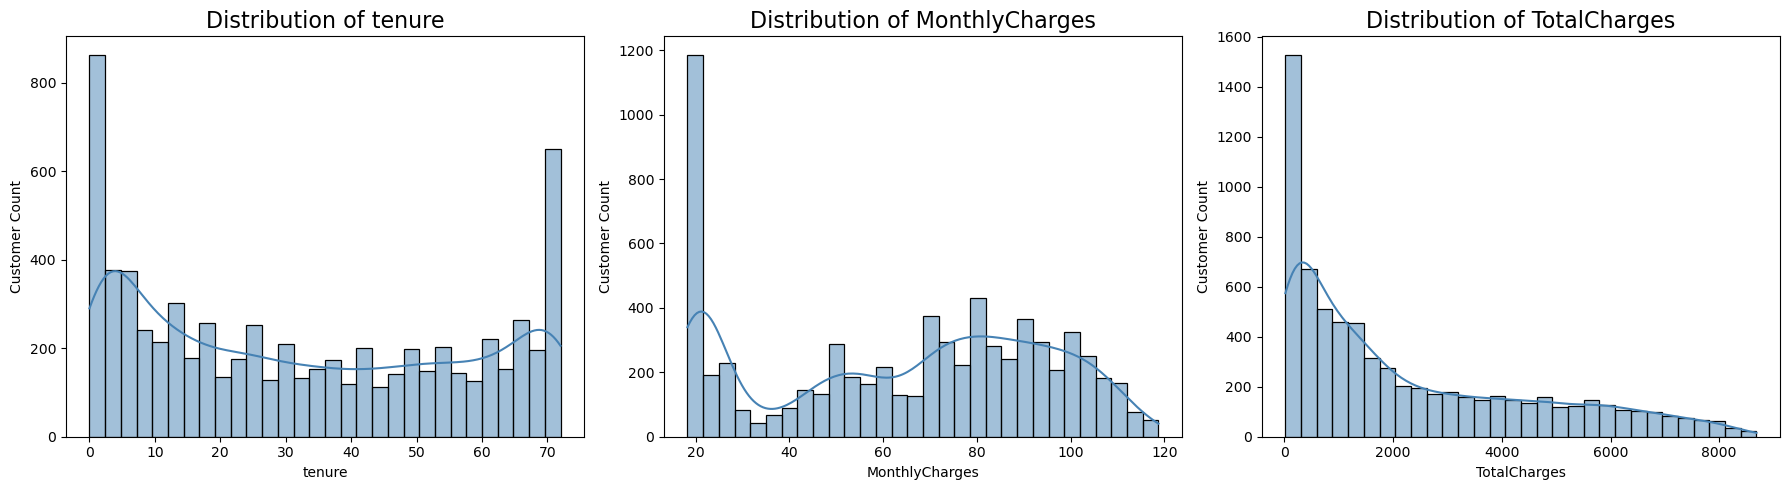

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, var in enumerate(numeric_features):
    sns.histplot(data=df, x=var, bins=30, kde=True,
                 color='steelblue', edgecolor='black', ax=axes[i])
    axes[i].set_title(f'Distribution of {var}', fontsize=16)
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('Customer Count')

plt.tight_layout()
plt.savefig('images/numeric_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

> **Key Insights — Numeric Features** 📊  
> - **`tenure`** ranges 0-72 months (median 29, mean 32.4) and is **bimodal**: a large spike at months around 0 (recent signups) and another at months around 70. The upper spike is partly an observation-window effect, since the data spans about 72 months, so long-standing customers pile up at the cap. 
> - **`MonthlyCharges`** averages $\$64.76$ (std ≈ $\$30.09$) across a range of $\$18.25–\$118.75$. The distribution is **bimodal** but asymmetric— a low-price cluster near $\$20$ (likely phone-only or basic-tier customers) and a broad $\$70–\$100$ (likely fiber or bundled-service customers). The median ($\$70.35$) sits above the mean ($\$64.76$), consistent with the large low-price cluster pulling the mean down.
> - **`TotalCharges`** shows 7,032 non-null values against 7,043 total rows → **11 missing values**. These correspond to customers with `tenure = 0` who haven't been billed yet. These are structurally missing and are filled with 0 (see the imputation step below). It is **clearly right-skewed** with a spike near zero: mean $\$2,283$, median $\$1,397$, std ≈ $\$2,267$, max $\$8,684$. The distribution is essentially `tenure × MonthlyCharges` compounded — a small fraction of long-tenure high-bill customers drives the mean far above the median.
> - No missing values in `tenure` or `MonthlyCharges`; `TotalCharges` has the 11 structurally missing values noted above.
> - ⚠️ **Collinearity warning:** `TotalCharges ≈ tenure × MonthlyCharges`. This might cause strong correlation in Phase 3, which may affect XGBoost gain rankings and Logistic Regression coefficient stability.

### Diagnostics on categorical Features

In [15]:
for var in categorical_features:
    var_diagnostic(df, var)

--------------- Diagnostic Info: gender ---------------
Variable Type:   object
Missing values:  0
Value counts:
        count    pct
gender              
Male     3555  50.48
Female   3488  49.52
------------------------- End -------------------------
--------------- Diagnostic Info: SeniorCitizen ---------------
Variable Type:   category
Missing values:  0
Value counts:
               count    pct
SeniorCitizen              
No              5901  83.79
Yes             1142  16.21
------------------------- End -------------------------
--------------- Diagnostic Info: Partner ---------------
Variable Type:   object
Missing values:  0
Value counts:
         count   pct
Partner             
No        3641  51.7
Yes       3402  48.3
------------------------- End -------------------------
--------------- Diagnostic Info: Dependents ---------------
Variable Type:   object
Missing values:  0
Value counts:
            count    pct
Dependents              
No           4933  70.04
Yes        

### Visualization

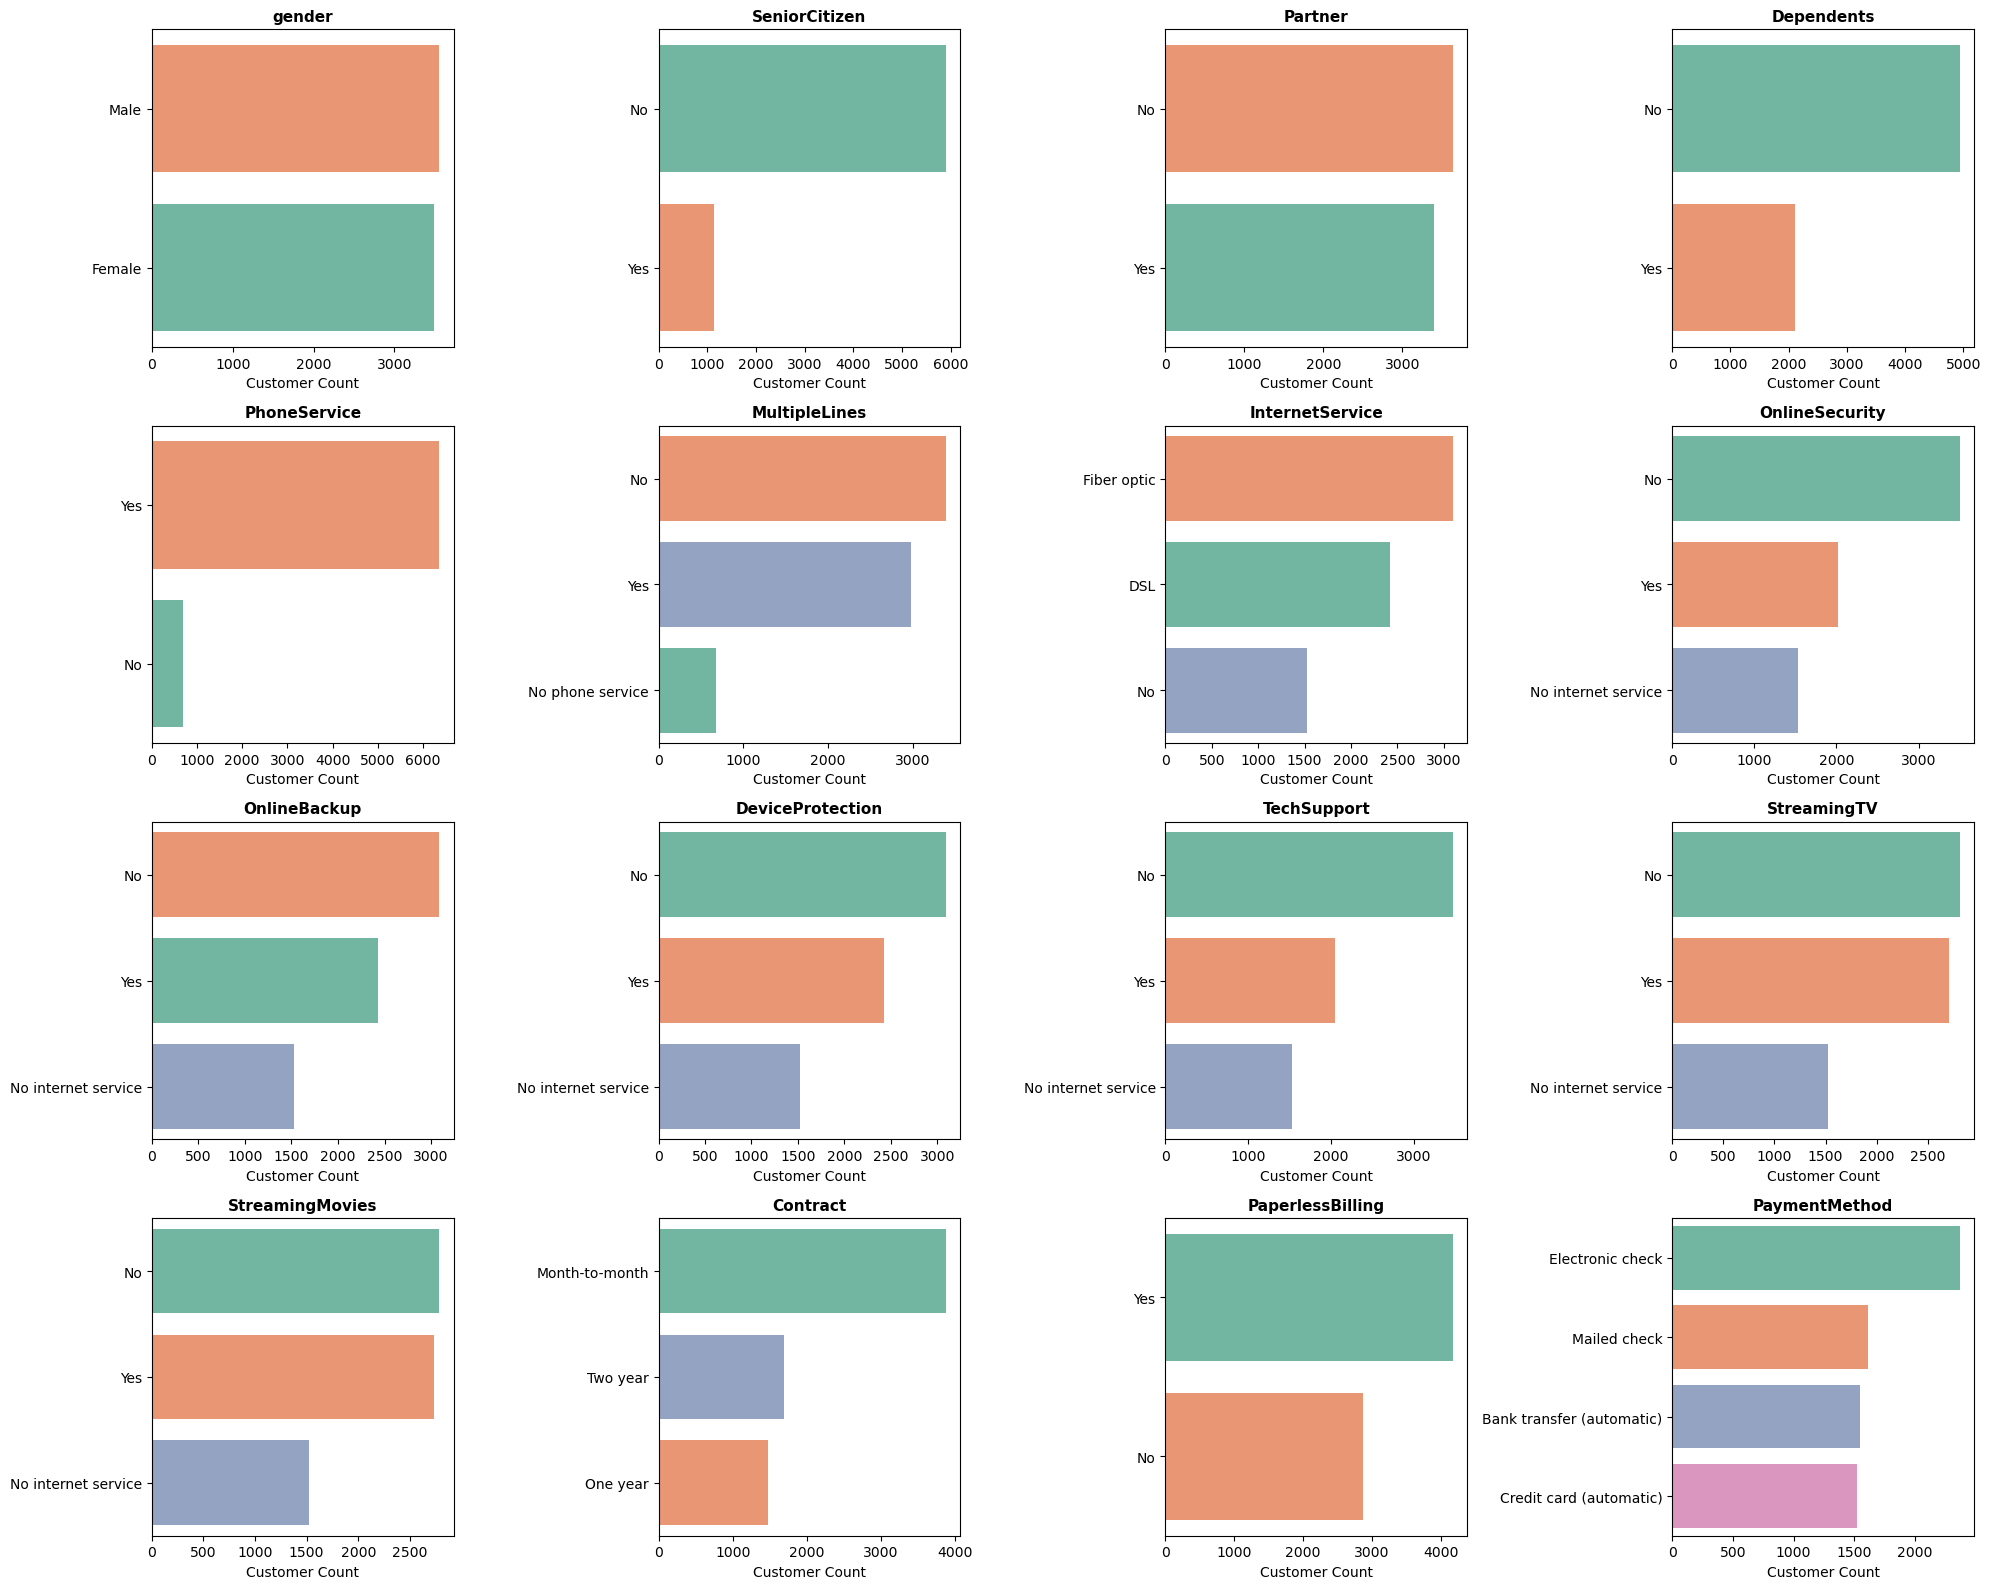

In [16]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for i, var in enumerate(categorical_features):
    ax = axes[i]
    order = df[var].value_counts().index
    sns.countplot(data=df, y=var, order=order, ax=ax,
                  hue=var, palette='Set2', legend=False)
    ax.set_title(var, fontsize=11, fontweight='bold')
    ax.set_xlabel('Customer Count')
    ax.set_ylabel('')

# Hide any unused subplot slots (none here — 16 features, 16 slots)
for j in range(len(categorical_features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('images/categorical_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

In [17]:
# Internet-service redundancy check
n_ol = (df['OnlineSecurity'] == 'No internet service').sum()
n_is = (df['InternetService'] == 'No').sum()
print(f"OnlineSecurity 'No internet service': {n_ol}, InternetService 'No': {n_is}")
assert n_ol == n_is, "Redundancy check failed: OnlineSecurity vs InternetService mismatch!"

# Phone-service redundancy check
n_ml = (df['MultipleLines'] == 'No phone service').sum()
n_ps = (df['PhoneService'] == 'No').sum()
print(f"MultipleLines 'No phone service': {n_ml}, PhoneService 'No': {n_ps}")
assert n_ml == n_ps, "Redundancy check failed: MultipleLines vs PhoneService mismatch!"

# These are count-level check. We should also check row-level equivalence
assert (df['OnlineSecurity'] == 'No internet service').equals(df['InternetService'] == 'No'), \
    "Rows mismatch: OnlineSecurity and InternetService redundancy is not exact!"

OnlineSecurity 'No internet service': 1526, InternetService 'No': 1526
MultipleLines 'No phone service': 682, PhoneService 'No': 682


> **Key Insights — Categorical Features** 📊
> - **No missing values** across all 16 categorical features.
> - **Redundant category detected:** seven features (`MultipleLines`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) contain a **"No internet service"** (six features) or **"No phone service"** (`MultipleLines`) level. These levels exactly duplicate `InternetService = No` and `PhoneService = No`, so one-hot encoding them would create duplicate columns (six identical copies of `InternetService_No` and one copy of `PhoneService_No`). They will be collapsed into "No" before encoding.
> - **Low-variance flag:** `PhoneService` is 90.3% Yes — expect weak XGBoost gain. `gender` is 49.5 / 50.5, a natural sanity check: if XGBoost ranks it highly, the pipeline has a problem.
> - **High-signal candidates:** `Contract` (55% month-to-month), `InternetService` (44% fiber optic), and `PaymentMethod` (34% electronic check) align with well-documented churn drivers in telecom and are the leading predictors to watch in Phase 4.
> - **Cardinality is low** (2-4 levels per feature). After collapsing the redundant levels ("No internet service", "No phone service"), one-hot encoding yields 36 columns (20 with `drop_first=True`), alongside the 3 numeric features. With $n = 4,930$ training rows this is a low-dimensional setting for logistic regression and tree-based models; it is a mild concern only for distance-based methods such as KNN  (the KNN comparison is restricted to the 13 top-ranked features).

### Diagnostics on the Target Variable

In [18]:
var_diagnostic(df, target)

--------------- Diagnostic Info: Churn ---------------
Variable Type:   category
Missing values:  0
Value counts:
       count    pct
Churn              
No      5174  73.46
Yes     1869  26.54
------------------------- End -------------------------


#### Visualization

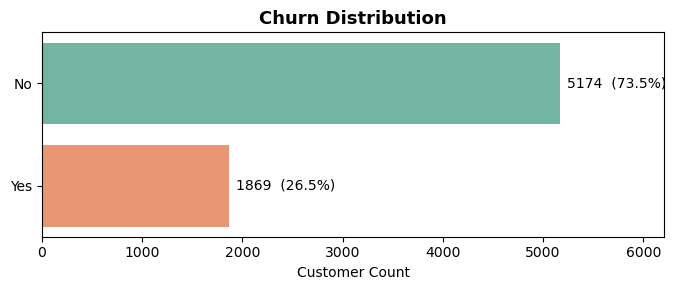

In [19]:
fig, ax = plt.subplots(figsize=(7, 3))

order = df[target].value_counts().index
sns.countplot(data=df, y=target, order=order,
              hue=target, palette='Set2', legend=False, ax=ax)

total = len(df)
for container in ax.containers:
    labels = [f'{bar.get_width():.0f}  ({bar.get_width()/total*100:.1f}%)'
              for bar in container]
    ax.bar_label(container, labels=labels, padding=5)

ax.set_title('Churn Distribution', fontsize=13, fontweight='bold')
ax.set_xlabel('Customer Count')
ax.set_ylabel('')
ax.set_xlim(0, df[target].value_counts().max() * 1.2)

plt.tight_layout()
plt.savefig('images/target_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [20]:
df[df[target] == 'Yes']['MonthlyCharges'].mean()

np.float64(74.44133226324237)

> **Key Insights — Target Variable (Churn)** 📊
> - **Class imbalance confirmed:** 5,174 customers stayed (73.5%) vs. 1,869 churned (26.5%), a ratio of about 2.8:1.
> - This imbalance is typical of real-world telecom attrition but has two modeling consequences:
>   1. **Accuracy is a misleading metric.** A naive classifier predicting "No" for everyone would score 73.5% accuracy while catching zero churners. Evaluation will lead with **Recall, F1, and PR-AUC** (whose no-skill baseline is the churn rate, 0.265), not accuracy.
>   2. **The train/test split must be stratified** (`train_test_split(stratify=y)`) so both sets keep the 26.5% churn rate.
> - **Handling imbalance will be made later.** Class weighting (e.g., `class_weight='balanced'`) is optional and has a cost: it shifts predicted probabilities upward (with balanced weights, the odds are inflated by about 2.8×), which would overstate the financial impact in the business simulation. If used, probabilities must be recalibrated before they feed the simulation. Because `KNeighborsClassifier` has no class-weight option, both models should handle imbalance in the same way (e.g., threshold tuning) so the comparison is fair.
> - The 26.5% churn rate leaves the positive class well represented (1,869 examples), so resampling (SMOTE, undersampling) is not strictly required.
> - **Business framing:** each of the 1,869 churned customers represents lost recurring revenue. At an average `MonthlyCharges` of about $\$74$, this cohort accounts for roughly **\$139K in monthly revenue leakage** for a sample of 7,043 customers, the target the retention strategy must address.

### Outlier Detection

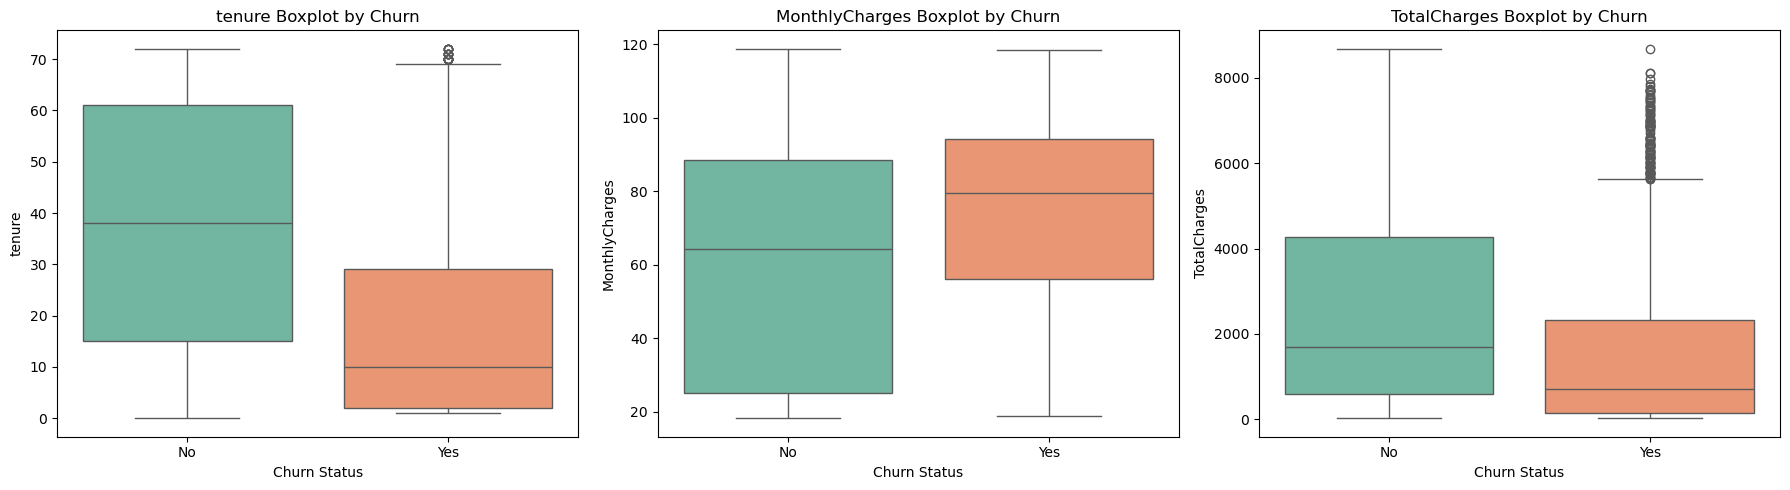

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df_plot = df.copy()

for i, var in enumerate(numeric_features):
    sns.boxplot(data=df_plot, x='Churn', y=var, hue='Churn',
                palette='Set2', ax=axes[i], legend=False)
    axes[i].set_title(f'{var} Boxplot by Churn')
    axes[i].set_xlabel('Churn Status')
    axes[i].set_ylabel(var)

plt.tight_layout()
plt.savefig('images/features_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()

In [22]:
def upper_fence_population(df, var):
    """IQR upper fence computed on the entire customer base."""
    q1 = df[var].quantile(0.25)
    q3 = df[var].quantile(0.75)
    iqr = q3 - q1
    return q3 + 1.5 * iqr

for var in numeric_features:
    fence = upper_fence_population(df, var)
    flagged = df[(df['Churn'] == 'Yes') & (df[var] > fence)]
    print(f"{var}: population fence = {fence:.2f}, flagged churners = {len(flagged)}")

tenure: population fence = 124.00, flagged churners = 0
MonthlyCharges: population fence = 171.38, flagged churners = 0
TotalCharges: population fence = 8884.67, flagged churners = 0


> **Key Insights — Outlier Detection** 📊
> - **Method note:** Fences use the IQR rule applied to the **full customer base (n = 7,043)**. 
> - **`tenure`:** Population upper fence = **124 months**, well above the observed maximum of 72. **0 churned customers flagged.** Customers at the 72-month cap are at the maximum observable tenure, not anomalies.
> - **`MonthlyCharges`:** Population upper fence = **\\$171.38**, above the observed maximum of \\$118.75. **0 churned customers flagged.** Monthly bill alone does not isolate anomalous churners.
> - **`TotalCharges`:** Population upper fence = **\\$8,868.67**, above the observed maximum of \\$8,684.80. **0 churned customers flagged.** The long right tail of `TotalCharges` is the long-tenure, high-spend tail of the *normal* customer base — not a set of outliers.
> - **Why 0 flags on all three features?** For a right-skewed variable like `TotalCharges`, the IQR fence on the full base sits beyond the observed maximum. This is the honest outcome of the method: the dataset contains no statistical outliers in the numeric columns. Any "high-value churner" segment is better defined by a business rule (e.g., top-quartile `MonthlyCharges` + above-median `tenure`) than by an IQR flag.
> - **Cross-feature sanity check:** `TotalCharges ≈ tenure × MonthlyCharges` still holds across the dataset, so any customer with a large `TotalCharges` reflects long tenure combined with a high monthly bill — a structural consequence of how the column is built, not an independent pattern.
> - **Decision:** **No rows are removed for outlier treatment.** The arithmetic-consistency check in the following cell remains useful as a dataset-wide billing-integrity check (`tenure × MonthlyCharges ≈ TotalCharges` across all customers), not as a rescue of a false-positive segment.

### Missing `TotalCharges` Values & Imputation

In [23]:
missing = df[df['TotalCharges'].isna()]
print(len(missing), "\n")
print(missing[['tenure', 'MonthlyCharges', 'Churn']].describe(include='all'))
print("\n", missing['Churn'].value_counts())
print("\n", (df['tenure'] == 0).sum())

11 

        tenure  MonthlyCharges Churn
count     11.0       11.000000    11
unique     NaN             NaN     1
top        NaN             NaN    No
freq       NaN             NaN    11
mean       0.0       41.418182   NaN
std        0.0       23.831484   NaN
min        0.0       19.700000   NaN
25%        0.0       20.125000   NaN
50%        0.0       25.750000   NaN
75%        0.0       58.975000   NaN
max        0.0       80.850000   NaN

 Churn
No     11
Yes     0
Name: count, dtype: int64

 11


In [24]:
# TotalCharges is structurally missing iff tenure = 0, not random.
mask = df['TotalCharges'].isna() & (df['tenure'] == 0)
df.loc[mask, 'TotalCharges'] = 0.0

assert df['TotalCharges'].isna().sum() == 0, "Unexpected missing TotalCharges remain"
print(f"Filled {mask.sum()} structurally missing TotalCharges values with 0")

Filled 11 structurally missing TotalCharges values with 0


> **Key Insights — Missing Values** 📊
> - **11 customers have a missing `TotalCharges`, and all 11 have `tenure = 0`.** These are brand-new customers who have not yet been billed, so the value is structurally missing, not random.
> - **Imputed with 0, not the mean or median.** A mean or median fill (roughly $\$1,400$ to $\$2,300$) would invent lifetime revenue for customers who have paid nothing, and would create a combination that cannot exist (zero tenure with high lifetime spend). The fill is a fixed rule, so it introduces no train/test leakage.
> - **All 11 are non-churners (`Churn = No`).** A customer with zero months of tenure has had no time to leave, so these rows carry no information about churn behavior. They are kept so that the class counts (5,174 / 1,869) are unchanged.

### Data Quality Assurance  
Final validation pass before modeling: three assertion checks confirm there are no negative charges or tenure values, that the 11 imputed zero-tenure customers are consistently recorded, and that TotalCharges is plausible relative to tenure × MonthlyCharges. Any violation raises an error immediately, so downstream analysis cannot silently proceed on corrupted data.

In [25]:
# Negative Balance Check
assert df[(df['MonthlyCharges'] < 0) | (df['TotalCharges'] < 0)].shape[0] == 0, \
    "Data Error: Negative charges exist in the dataset!"
assert df[df['tenure'] < 0].shape[0] == 0, \
    "Data Error: Negative tenure values!"

print("✅ No negative charges and no negative tenure values.")

✅ No negative charges and no negative tenure values.


In [26]:
# New Customer Balance Check
assert df[(df['tenure'] == 0) & (df['TotalCharges'] > 0)].shape[0] == 0, \
    "Logic Error: Customers with 0 tenure have Total Charges > $0"

print("✅ No new customers with non-zero TotalCharges.")

✅ No new customers with non-zero TotalCharges.


---
## <center> Objective 1: </center>
### <center> What is the descriptive relationship between customer attributes and churn status? </center>
---  
**Methodological Approach**
- **Categorical features (16):** churn rate per category level, benchmarked against the overall 26.5% baseline.
- **Numeric features (3):** mean comparison between churned and retained customers.
- **Correlation:** Pearson for numeric pairs; Cramér's V for categorical associations.
- **Distribution:** numeric features overlaid by churn status to reveal separation.

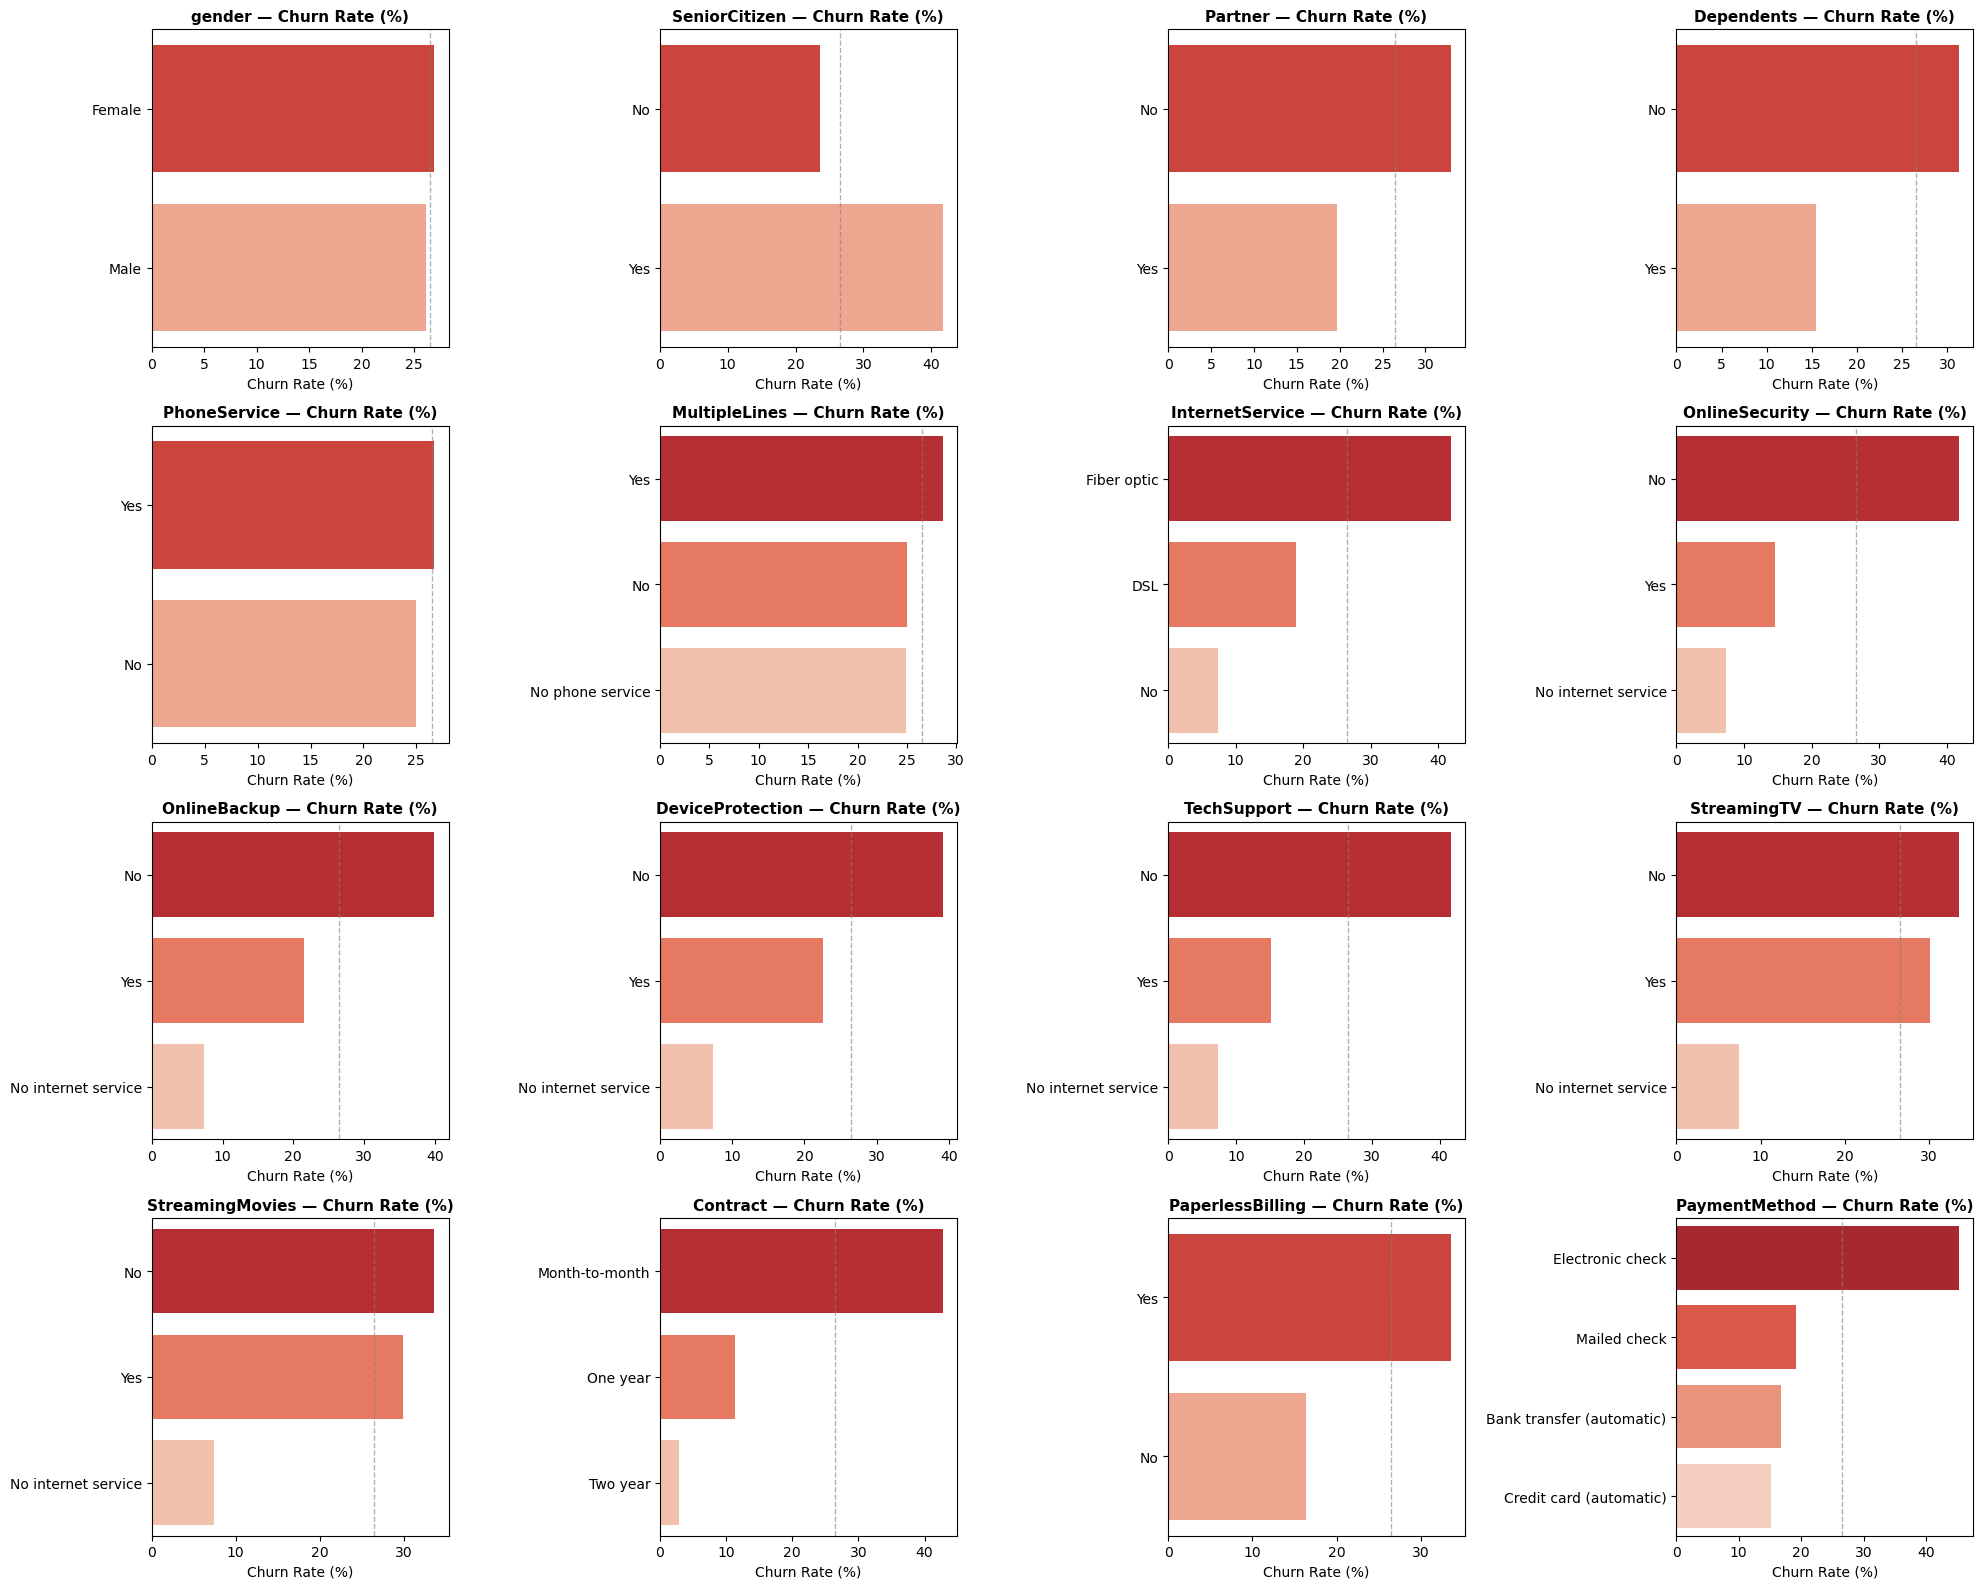

In [27]:
# Churn rate by categorical feature
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for i, var in enumerate(categorical_features):
    ax = axes[i]
    churn_rate = df.groupby(var, observed=True)['Churn'].apply(
        lambda s: (s == 'Yes').mean() * 100
    ).sort_values(ascending=False)

    sns.barplot(x=churn_rate.values, y=churn_rate.index, ax=ax,
                hue=churn_rate.index, palette='Reds_r', legend=False)
    ax.set_title(f'{var} — Churn Rate (%)', fontsize=11, fontweight='bold')
    ax.set_xlabel('Churn Rate (%)')
    ax.set_ylabel('')
    ax.axvline(x=26.5, color='gray', linestyle='--', alpha=0.6, linewidth=1)

for j in range(len(categorical_features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('images/churn_rate_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

> **Key Insights — Churn Rate by Categorical Feature** 📊
> - **`Contract` is the strongest single separator:** month-to-month customers churn at \~43%, roughly **14× the rate** of two-year contract holders (~3%). Contract type is expected to rank #1 in XGBoost gain.
> - **`InternetService`:** fiber optic churns at \~42%, more than **double** DSL (~19%). Customers with no internet service churn at ~7% — the most stable segment.
> - **`PaymentMethod`:** electronic check churns at \~45%, over **3× higher** than automatic payment methods (~15–17%). Manual payment correlates with higher attrition.
> - **Add-on services (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`):** customers without these services churn at ~40%+, while subscribers churn at ~15–22%. Absence of value-added services is a strong churn marker.
> - **Demographics are mixed: only `gender` is flat.** `gender` shows essentially no separation (Female and Male both sit at about the 26.5% baseline). The other three demographics do separate churn: SeniorCitizen = Yes churns at about 42% vs. about 24% for No; Partner = No at about 33% vs. about 20% for Yes; Dependents = No at about 31% vs. about 15% for Yes. Partner and Dependents likely overlap with tenure and contract type (customers living alone may be younger accounts on month-to-month plans), so their standalone effect is probably smaller than these raw rates suggest. (This matches the XGBoost ranking later, where `SeniorCitizen_Yes` is retained.)
> - **`PhoneService` / `MultipleLines`:** modest separation. `PhoneService = No` churns lower (~25%), but the effect is small compared to contract, internet, or payment method.
> - **PaperlessBilling:** customers on paperless billing churn at about 34%, roughly double the rate of those on paper bills (about 16%). The gap is as large as the demographic ones, and it fits the manual-payment pattern: electronic billing and electronic checks may both reflect lower-commitment customers. The XGBoost ranking later retains `PaperlessBilling_Yes` (#8), consistent with this.
> - **Pattern:** the highest-churn levels cluster around **flexibility and low commitment** — no contract, no add-ons, manual payment. XGBoost feature selection should rank these commitments-related features near the top.

In [28]:
# Compare mean numeric values between churned and retained customers
group_means = df.groupby('Churn', observed=True)[numeric_features].mean().T
group_means.columns = ['Stayed (No)', 'Churned (Yes)']
group_means['Difference'] = group_means['Churned (Yes)'] - group_means['Stayed (No)']
print(group_means.round(2))

                Stayed (No)  Churned (Yes)  Difference
tenure                37.57          17.98      -19.59
MonthlyCharges        61.27          74.44       13.18
TotalCharges        2549.91        1531.80    -1018.12


> **Key Insights — Numeric Features by Churn Status** 📊
> - **`tenure`:** churned customers averaged **18.0 months** vs. **37.6 months** for retained customers — a **19.6-month gap**. Short-tenure customers are the primary churn population, consistent with the bimodal distribution (early defectors) observed in diagnostics.
> - **`MonthlyCharges`:** churned customers paid **\$74.44/month** vs. **\$61.27** for retained — a **\$13.18 premium**. Higher bills correlate with higher churn, suggesting price sensitivity or perceived value gap.
> - **`TotalCharges`:** churned customers accumulated **\$1,532** in lifetime spend vs. **\$2,550** for retained — a **\$1,018 gap**. This is largely a *consequence* of shorter tenure, not an independent driver: less time = less cumulative billing.
> - **Direction:** churn is associated with **short tenure + high monthly bill + low cumulative spend**. The high-bill/short-tenure combination represents new customers paying top dollar — the highest-priority segment for retention, since they carry both high revenue value and high exit risk.
> - **Collinearity reminder:** `TotalCharges` ≈ `tenure` × `MonthlyCharges`, so its separation is not independent evidence — it's arithmetic. Its gain ranking later should be read with that overlap in mind.

### Correlation Matrix for Numeric Features

                tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.248         0.826
MonthlyCharges   0.248           1.000         0.651
TotalCharges     0.826           0.651         1.000


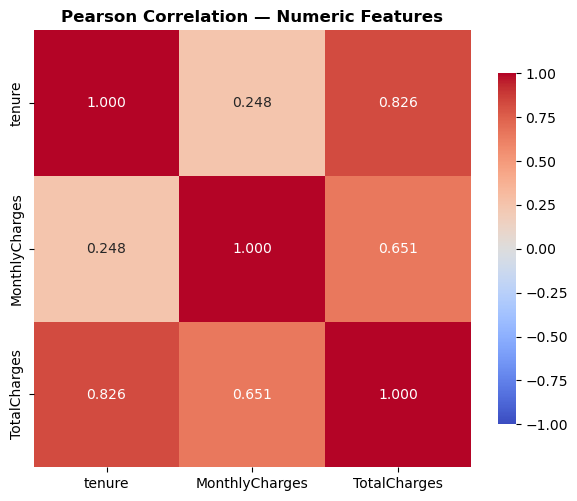

In [29]:
# Pearson correlation between numeric features
corr_matrix = df[numeric_features].corr()
print(corr_matrix.round(3))

# Heatmap
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Pearson Correlation — Numeric Features', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('images/correlation_numeric.png', dpi=300, bbox_inches='tight')
plt.show()

> **Key Insights — Pearson Correlation (Numeric)** 📊
> - **`tenure` ↔ `TotalCharges` = ~0.83** — very strong positive correlation. Longer-tenured customers accumulate more lifetime charges, as expected.
> - **`MonthlyCharges` ↔ `TotalCharges` = ~0.65** — moderate-strong. Higher monthly bills inflate cumulative charges over time.
> - **`tenure` ↔ `MonthlyCharges` = ~0.25** — weak. Time with the company and monthly price are largely independent, which is good news for modeling: the two strongest numeric predictors do not duplicate each other.
> - **Collinearity risk confirmed.** With `tenure` and `TotalCharges` at 0.83, including both in Logistic Regression could inflate standard errors on their coefficients. This is a candidate for attention during feature selection — XGBoost may rank one over the other, or LR coefficients may need interpretation with care.
> - **Implication for modeling:** the near-collinear pair (`tenure`, `TotalCharges`) shares predictive signal; the independent pair (`tenure`, `MonthlyCharges`) contributes distinct information.

### Cramér's V (Categorical Associations) 📏
>
> Association between pairs of categorical features is measured with **Cramér's V**, which rescales the chi-square statistic of the contingency table to the range 0 to 1:
>
> $$V = \sqrt{\frac{\chi^2 / n}{\min(r-1,\; k-1)}}$$
>
> where $\chi^2$ is the Pearson chi-square statistic of the cross-tabulation of the two features, $n$ is the number of observations, and $r$ and $k$ are the numbers of categories of each feature.
> - **Interpretation:** $V = 0$ means the two features are independent; $V = 1$ means one feature fully determines the other. $V$ is symmetric and unsigned, so it shows the strength of association but not its direction.
> - **Implementation:** `chi2_contingency` returns four things: the statistic ([0]), the p-value, the degrees of freedom and the expected counts. The statistic (below) is computed without Yates' continuity correction (`correction=False`). The matrix is symmetric, with a diagonal of 1.
> - **Caveat:** $V$ is biased upward in small samples and for features with many categories. With $n = 7,043$ and 2–4 levels per feature, this bias is negligible here.

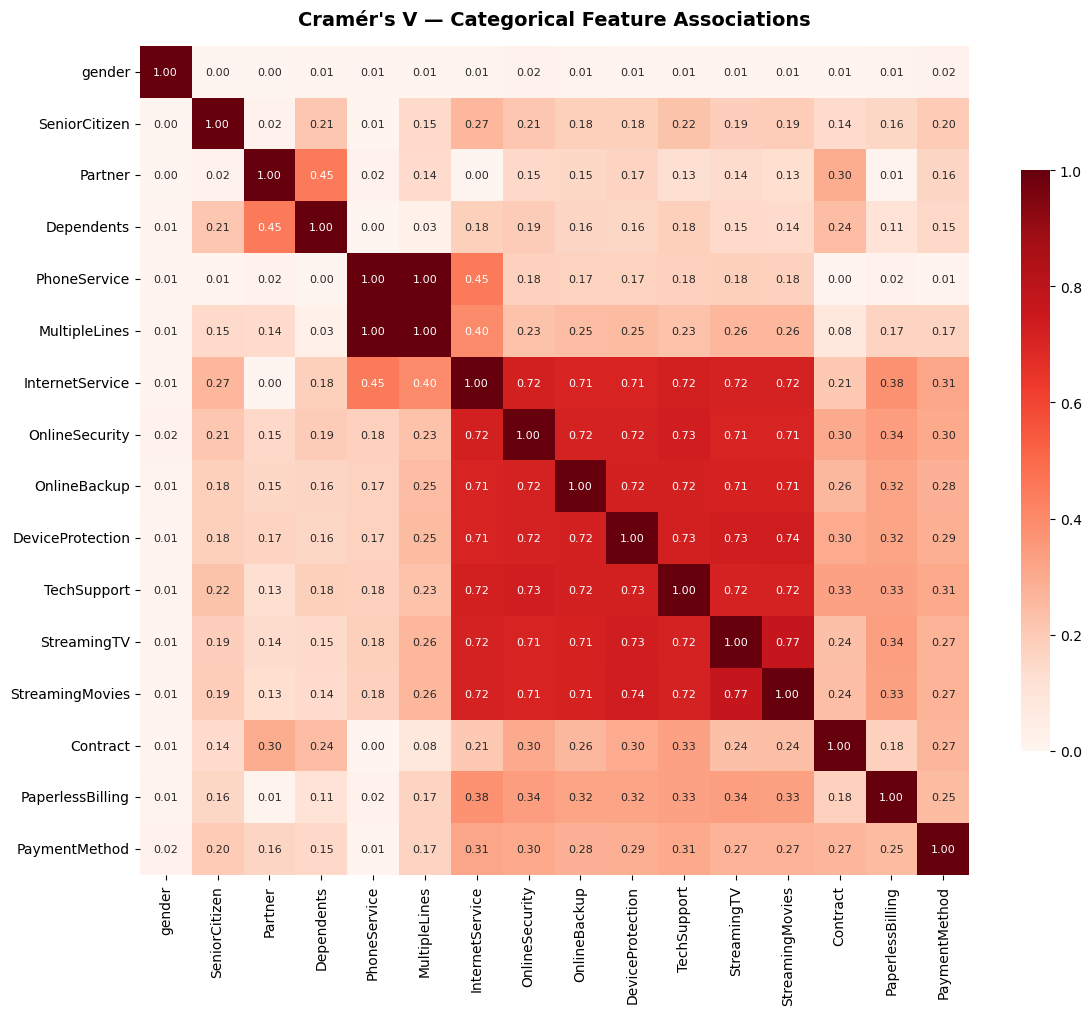

In [30]:
def cramers_v(x, y):
    """Cramér's V association between two categorical series."""
    confusion = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion, correction=False)[0]
    n = confusion.sum().sum()
    r, k = confusion.shape
    return np.sqrt((chi2 / n) / min(r - 1, k - 1))

# Build the symmetric association matrix
cramerv_matrix = pd.DataFrame(index=categorical_features,
                         columns=categorical_features, dtype=float)

for i in categorical_features:
    for j in categorical_features:
        cramerv_matrix.loc[i, j] = cramers_v(df[i], df[j])

# Heatmap
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cramerv_matrix.astype(float), annot=True, fmt='.2f',
            cmap='Reds', vmin=0, vmax=1, square=True,
            cbar_kws={'shrink': 0.7}, ax=ax,
            annot_kws={'size': 8})
ax.set_title("Cramér's V — Categorical Feature Associations",
             fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('images/cramers_v_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

> **Key Insights — Cramér's V (Categorical Associations)** 📊
> - **Internet-service cluster (~0.71–0.77):** `InternetService` and its six add-on services (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) form a tightly-coupled block with pairwise V of ~0.7. This is largely **structural redundancy** — the "No internet service" level appears identically across all seven columns, inflating their association. Collapsing those levels to "No" (as planned) will reduce these values but not eliminate them: real correlation remains between which add-ons customers subscribe to.
> - **`PhoneService` ↔ `MultipleLines` = 1.00:** Perfect association. `MultipleLines` is entirely determined by `PhoneService = No` → "No phone service." One of the two is redundant for modeling — XGBoost will likely pick one and ignore the other.
> - **`Partner` ↔ `Dependents` = 0.45:** Moderate. Customers with a partner are more likely to have dependents — a natural demographic correlation, not a data issue.
> - **`Contract` has weak to moderate associations (V ≈ 0.15–0.30):** It shows only weak-moderate association with everything else, including the internet-service cluster. This is good news — `Contract` carries **distinct** signal and is not duplicating information from other features. Consistent with it being a top churn driver.
> - **`gender` is nearly orthogonal to everything (V ≈ 0.00–0.02):** Confirms the earlier flag — `gender` is a very weak predictor with essentially no association to any other feature.
> - **`PaymentMethod` is moderately associated with everything (~0.25–0.33):** No single dominant pairing. It carries broad but diffuse signal.
> - **Implication for XGBoost:** The strongest churn drivers from the bar charts (`Contract`, `InternetService`, `PaymentMethod`) show **low-to-moderate cross-correlation** with each other, meaning each contributes independent signal. XGBoost gain should rank these highly without redundant competition from collinear features.
> - **Implication for encoding:** Collapsing "No internet service" and "No phone service" levels is confirmed as the right call — the 1.00 association on `PhoneService`/`MultipleLines` alone justifies removing the redundancy before one-hot encoding.

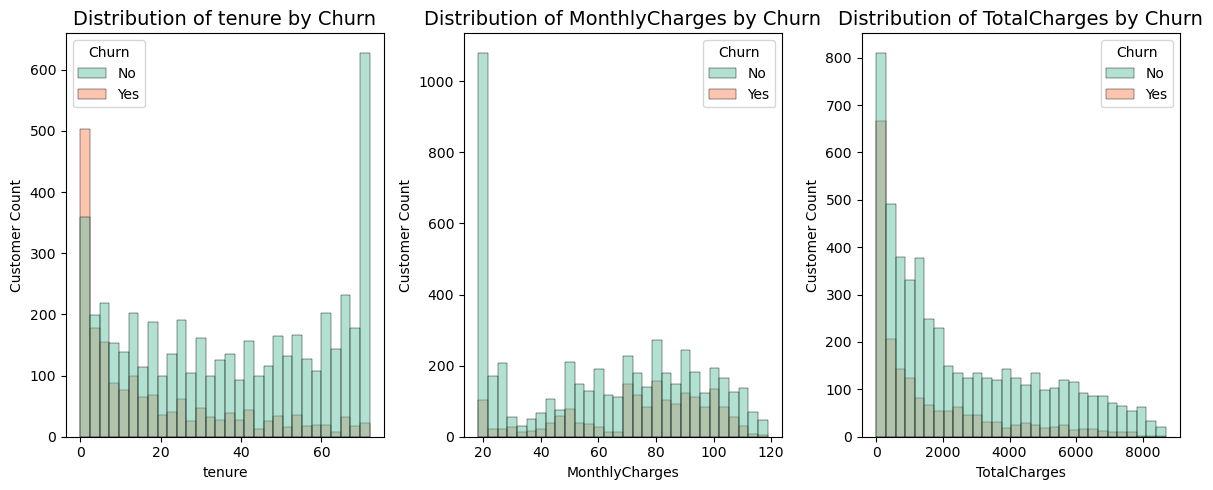

In [31]:
# Numeric features overlaid by churn status
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for i, var in enumerate(numeric_features):
    sns.histplot(data=df, x=var, hue='Churn', palette='Set2',
                 multiple='layer', alpha=0.50, bins=30,
                 edgecolor='black', linewidth=0.3, ax=axes[i])
    axes[i].set_title(f'Distribution of {var} by Churn', fontsize=14)
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('Customer Count')

plt.tight_layout()
plt.savefig('images/numeric_by_churn.png', dpi=300, bbox_inches='tight')
plt.show()

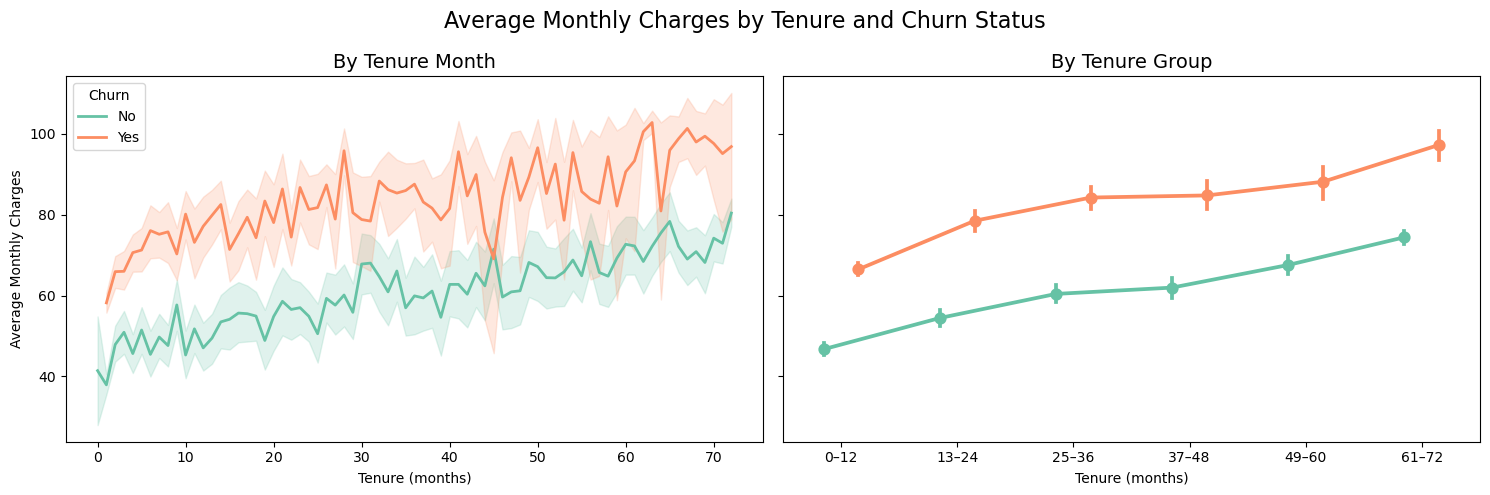

In [32]:
# Mean monthly charges by tenure, split by churn status
tenure_bin = pd.cut(df['tenure'], bins=[-1, 12, 24, 36, 48, 60, 72],
                    labels=['0–12', '13–24', '25–36', '37–48', '49–60', '61–72'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# Left: mean monthly charges at each tenure month
sns.lineplot(data=df, x='tenure', y='MonthlyCharges', hue='Churn',
             palette='Set2', estimator='mean', errorbar=('ci', 95),
             linewidth=2, ax=axes[0])
axes[0].set_title('By Tenure Month', fontsize=14)
axes[0].set_xlabel('Tenure (months)')
axes[0].set_ylabel('Average Monthly Charges')

# Right: mean monthly charges per tenure group
sns.pointplot(data=df.assign(tenure_bin=tenure_bin), x='tenure_bin', y='MonthlyCharges',
              hue='Churn', palette='Set2', dodge=0.3, errorbar=('ci', 95), ax=axes[1])
axes[1].set_title('By Tenure Group', fontsize=14)
axes[1].set_xlabel('Tenure (months)')
axes[1].set_ylabel('')
axes[1].get_legend().remove()

fig.suptitle('Average Monthly Charges by Tenure and Churn Status', fontsize=16)
plt.tight_layout()
plt.savefig('images/tenure_monthly_charges_by_churn.png', dpi=300, bbox_inches='tight')
plt.show()

> **Key Insights — Numeric Features by Churn** 📊
> - `tenure`: churn concentrates in the first 0–15 months; retained customers cluster at 70+ months. Early tenure is the single clearest visual separator.
> - `MonthlyCharges`: churn skews toward high bills (\\$70–100); retention dominates the low-price cluster near \\$20. This is a marginal association, not evidence that price alone drives exit: high bills go with other risk factors such as fiber-optic service, and the multivariate model does not interpret MonthlyCharges on its own.
> - **Tenure × MonthlyCharges (line plot):** at almost every tenure level, churners pay roughly \$15–25 more per month than retained customers, and the two lines rise roughly in parallel. The higher bills of churners are therefore not a tenure artifact: the churner/non-churner gap stays about the same as tenure grows. The churner line is noisy beyond about 40 months, where few churners remain.
> - `TotalCharges`: churn peaks near \\$0 and drops steadily; retention dominates mid-to-high lifetime spend. Churners simply haven't been around long enough to accumulate charges — reinforcing that `tenure` is the underlying driver.

---
## <center> Objective 2: </center> 
### <center> Which features carry the strongest predictive signal for churn, as ranked by XGBoost gain importance across the full Telco feature set? </center>
---  

**Methodological Approach**
- **Collapse redundant levels** — merge "No internet service" / "No phone service" into "No" across the seven affected columns.
- **Encode the target** — map `Churn` "Yes"/"No" → 1/0 for model consumption.
- **Encode the predictors** — one-hot encode categorical features.
- **Stratified split** — 70/30 train/test with `random_state=60`, stratified on `Churn`.
- **Fit XGBoost** on the training set with sensible defaults + early stopping on a validation split from the training data.
- **Rank features by gain importance**.
- **Select the top-N features** by cumulative gain threshold (e.g., 95%).
- **Export** `selected_features.json` for Notebook 2.

In [33]:
# Collapse "No internet service" and "No phone service" to "No" for consistency
redundant_map = {'No internet service': 'No', 'No phone service': 'No'}

# Recoding the categories
for col in ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies']:
    df[col] = df[col].replace(redundant_map)

# Verify the collapse
for col in ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies']:
    print(f"{col}: {sorted(df[col].unique())}")

MultipleLines: ['No', 'Yes']
OnlineSecurity: ['No', 'Yes']
OnlineBackup: ['No', 'Yes']
DeviceProtection: ['No', 'Yes']
TechSupport: ['No', 'Yes']
StreamingTV: ['No', 'Yes']
StreamingMovies: ['No', 'Yes']


In [34]:
print(f"Value counts:\n{df['Churn'].value_counts()}")

# Encode Churn as binary (XGBoost requires numeric labels)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0}).astype('int')

# Verify
print(f"\nChurn dtype: {df['Churn'].dtype}")
print(f"\nValue counts:\n{df['Churn'].value_counts()}")
print(f"\nClass balance: {df['Churn'].mean():.4f}")

Value counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn dtype: int64

Value counts:
Churn
0    5174
1    1869
Name: count, dtype: int64

Class balance: 0.2654


In [35]:
# One-hot encode categorical predictors
# drop_first=True -> Drops the first level of each feature as the reference category,
# avoids perfect multicollinearity
df_encoded = pd.get_dummies(df, columns=categorical_features,
                            drop_first=True, dtype=int)

df = df.drop(columns='tenure_bin', errors='ignore')

# Dummy columns after encoding
dummy_cols = [c for c in df_encoded.columns if c not in df.columns]
passthrough_cols = [c for c in df_encoded.columns if c in df.columns]

print(f"Shape before encoding: {df.shape}")
print(f"Shape after encoding:  {df_encoded.shape}")
print(f"Original categorical columns:  {len(categorical_features)}")
print(f"Total encoded dummy columns:   {len(dummy_cols)}")
print(f"Net columns added:             {df_encoded.shape[1] - df.shape[1]}")
print(f"\nColumns passed through unchanged ({len(passthrough_cols)}):")
print(passthrough_cols)
print(f"\nEncoded dummy columns ({len(dummy_cols)}):")
print(dummy_cols)

Shape before encoding: (7043, 20)
Shape after encoding:  (7043, 24)
Original categorical columns:  16
Total encoded dummy columns:   20
Net columns added:             4

Columns passed through unchanged (4):
['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']

Encoded dummy columns (20):
['gender_Male', 'SeniorCitizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [36]:
# All dummies should be 0/1
assert df_encoded[dummy_cols].isin([0, 1]).all().all(), \
    "Non-binary values found in encoded columns!"
print(f"✅ All {len(dummy_cols)} encoded columns are binary.")

✅ All 20 encoded columns are binary.


In [37]:
assert (df_encoded.dtypes == 'object').sum() == 0, "Object dtypes remain!"
print("✅ All columns are numeric.")

✅ All columns are numeric.


In [38]:
# Separate predictors from target
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Feature count: {X.shape[1]}")
print(f"Churn rate:    {y.mean():.4f}")

X shape: (7043, 23)
y shape: (7043,)
Feature count: 23
Churn rate:    0.2654


In [39]:
# Stratified 70/30 split — preserves the 26.5% churn rate in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=60
)

print(f"X_train: {X_train.shape}   y_train churn rate: {y_train.mean():.4f}")
print(f"X_test:  {X_test.shape}    y_test  churn rate: {y_test.mean():.4f}")


X_train: (4930, 23)   y_train churn rate: 0.2653
X_test:  (2113, 23)    y_test  churn rate: 0.2655


### Modeling XGBoost for Feature Ranking ⚙️

**Note:** XGBoost is used here only as a *feature-ranking tool*, not as the final classifier. It will score all 23 encoded predictors by gain importance, and the top-ranked ones are passed to the models that answer the churn question in Notebook 2 (Logistic Regression and k-Nearest Neighbors).

- **Why XGBoost for selection?** Tree ensembles capture non-linear effects and interactions (e.g., contract type × tenure) without manual feature engineering, and they do not need scaling. A ranking based on linear coefficients alone could miss such effects.
- **Why select features at all?** Parsimony. A logistic regression with fewer variables is easier to explain and gives a shorter list of levers for retention action, and k-NN works better in a smaller feature space. 
- **Why gain importance?** Gain measures how much each feature reduces the training loss when it is used in a split. It is the default in XGBoost and is easy to explain as "share of total predictive improvement."
- **Leakage control.** The 70/30 split is stratified (`random_state=60`) and happens *before* any modeling. Only the training set is used: 80% to fit the trees and 20% as a validation set for early stopping. The test set is never used for selection.
- **Early stopping.** The training set is split again (80% fit / 20% validation, stratified) so that early stopping (30 rounds on log-loss) picks the number of trees. This avoids fitting noise, which would distort the ranking.
- **Conservative hyperparameters.** `max_depth=4`, `learning_rate=0.05`, `subsample=0.8` and `colsample_bytree=0.8` keep the trees shallow and regularized. The aim is a stable ranking, not maximum accuracy.
- **Robustness check.** The model will be refit under 5 different validation splits and seeds to check whether the top-12 set stays the same, since individual gain values are expected to move.

#### Limitations 

- **Gain is not standalone predictive power.** Correlated features split credit (`TotalCharges ≈ tenure × MonthlyCharges`, and tenure overlaps with contract type), so a low rank does not mean a weak predictor. Exact gain values will also shift between seeds; only the overall ordering is trusted.
- **No second importance method.** Permutation importance and SHAP will not be computed, and gain shows neither the direction of an effect nor causation. Direction is left to the Logistic Regression coefficients.
- **No tuning or evaluation of XGBoost itself.** There is no hyperparameter search, no class-imbalance handling (`scale_pos_weight`) and no test-set scoring, because the model is only a ranking tool. We make no claim about how well it predicts churn.

In [40]:
# Split the 70% training set again: 80% fit, 20% validation
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=60
)

xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    early_stopping_rounds=30,
    random_state=60,
    n_jobs=-1,
)
xgb_model.fit(
    X_fit, y_fit,
    eval_set=[(X_fit, y_fit), (X_val, y_val)],  
    verbose=False,
)
print(f"Best iteration: {xgb_model.best_iteration}")

Best iteration: 87


In [41]:
# Extract gain importance and rank
importance = pd.DataFrame({
    'feature':    X_train.columns,
    'gain':       xgb_model.feature_importances_,  
}).sort_values('gain', ascending=False).reset_index(drop=True)

# Add cumulative gain for later selection
importance['cumulative_gain'] = importance['gain'].cumsum() / importance['gain'].sum()
importance['cumulative_pct']  = (importance['cumulative_gain'] * 100).round(2)

# Print full table
print(importance.to_string(index=False))

                              feature     gain  cumulative_gain  cumulative_pct
                    Contract_Two year 0.212085         0.212085       21.209999
          InternetService_Fiber optic 0.207524         0.419609       41.959999
                    Contract_One year 0.123578         0.543188       54.320000
                   InternetService_No 0.060819         0.604006       60.400002
       PaymentMethod_Electronic check 0.049047         0.653053       65.309998
                               tenure 0.041947         0.695000       69.500000
                 PaperlessBilling_Yes 0.029960         0.724960       72.500000
                   OnlineSecurity_Yes 0.029631         0.754591       75.459999
                         TotalCharges 0.025541         0.780132       78.010002
                    SeniorCitizen_Yes 0.024227         0.804359       80.440002
                      StreamingTV_Yes 0.022653         0.827012       82.699997
                  StreamingMovies_Yes 0.

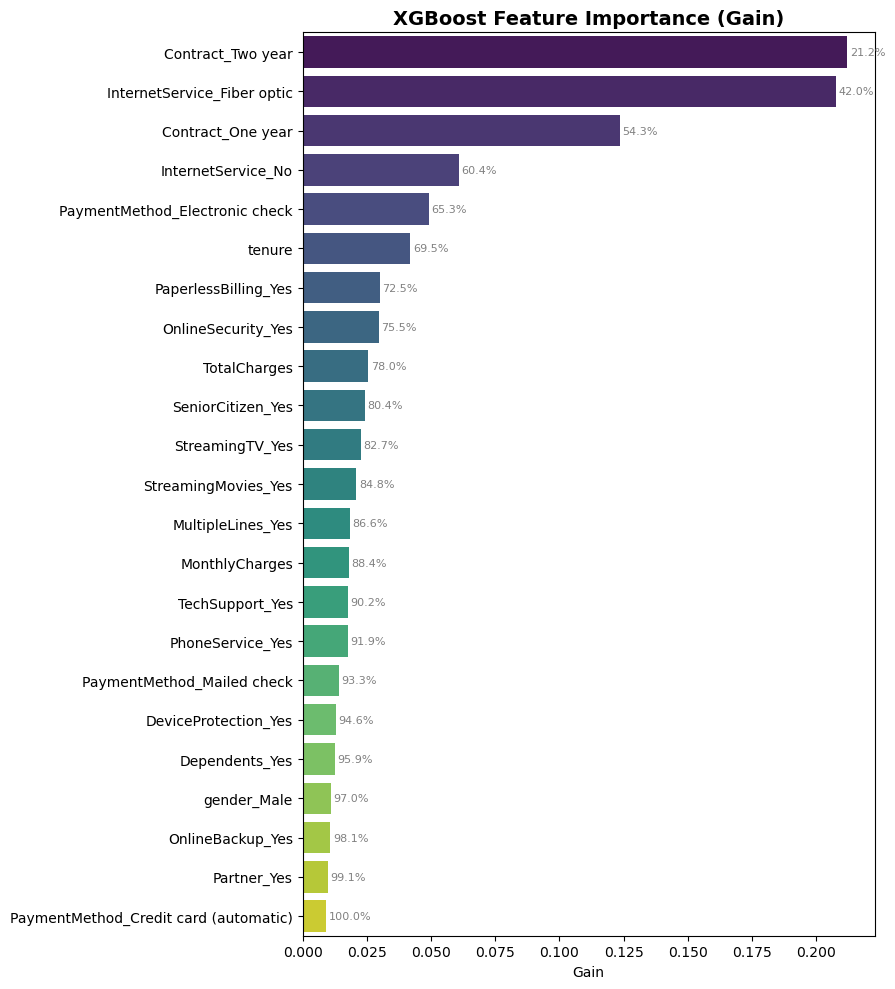

In [42]:
fig, ax = plt.subplots(figsize=(9, 10))

sns.barplot(data=importance, x='gain', y='feature',
            hue='feature', palette='viridis', legend=False, ax=ax)

ax.set_title('XGBoost Feature Importance (Gain)', fontsize=14, fontweight='bold')
ax.set_xlabel('Gain')
ax.set_ylabel('')

# Annotate cumulative gain on the right
for i, (g, cum) in enumerate(zip(importance['gain'], importance['cumulative_pct'])):
    ax.text(g + 0.001, i, f'{cum:.1f}%', va='center', fontsize=8, color='gray')

plt.tight_layout()
plt.savefig('images/xgb_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

#### Checking Interaction Effects  
**Screening rule (a rule of thumb).** A pair is carried forward to Notebook 2 only if (1) its total SHAP interaction strength (twice the mean |value| of one triangle of the matrix) is at least around 10% of the stronger feature's main effect, (2) it is not a built-in artifact (`TotalCharges ≈ tenure × MonthlyCharges`, or dummies of the same variable), and (3) it has a plausible business explanation. Ratios are read with care when the stronger main effect is small, because the percentage is then inflated. 

In [43]:
booster = xgb_model.get_booster()
inter = booster.predict(xgb.DMatrix(X_fit), pred_interactions=True)  # XGBoost internal data format (n, F+1, F+1)
inter = inter[:, :-1, :-1]                       # (n, F, F)

strength = np.abs(inter).mean(axis=0)            # mean |interaction| per feature pair
np.fill_diagonal(strength, 0)               

feats = X_fit.columns
pairs = (pd.DataFrame(strength, index=feats, columns=feats)
         .stack().reset_index())
pairs.columns = ['f1', 'f2', 'strength']
pairs = pairs[pairs.f1 < pairs.f2].sort_values('strength', ascending=False)

# Drop pairs from the same variable
pairs = pairs[pairs.f1.str.split('_').str[0] != pairs.f2.str.split('_').str[0]]
print(pairs.head(10))

                                 f1              f2  strength
414               Contract_Two year          tenure  0.031203
209     InternetService_Fiber optic    TotalCharges  0.028030
46                     TotalCharges          tenure  0.023204
25                   MonthlyCharges    TotalCharges  0.022441
416               Contract_Two year    TotalCharges  0.022194
23                   MonthlyCharges          tenure  0.020828
483  PaymentMethod_Electronic check          tenure  0.019150
207     InternetService_Fiber optic          tenure  0.018471
415               Contract_Two year  MonthlyCharges  0.018312
437            PaperlessBilling_Yes          tenure  0.018228


In [44]:
inter_full = booster.predict(xgb.DMatrix(X_fit), pred_interactions=True)
margin = booster.predict(xgb.DMatrix(X_fit), output_margin=True)

# Sanity check: all entries (incl. baseline) sum to the log-odds prediction
print("additivity error:", np.abs(inter_full.sum(axis=(1, 2)) - margin).max())
print("std of log-odds across customers:", margin.std().round(3))

inter = inter_full[:, :-1, :-1]
main = pd.Series(np.abs(inter).mean(axis=0).diagonal(), index=X_fit.columns)
print(main.sort_values(ascending=False).head(10).round(3))

# Interaction as a share of the stronger feature's main effect
pairs['pair_total'] = 2 * pairs['strength']
pairs['vs_main'] = pairs['pair_total'] / pairs[['f1', 'f2']].apply(
    lambda r: max(main[r.f1], main[r.f2]), axis=1)
print(pairs.head(10).round(3))

additivity error: 5.2452087e-06
std of log-odds across customers: 1.738
Contract_Two year                 0.544
tenure                            0.437
InternetService_Fiber optic       0.361
PaymentMethod_Electronic check    0.211
Contract_One year                 0.185
MonthlyCharges                    0.160
TotalCharges                      0.143
PaperlessBilling_Yes              0.135
OnlineSecurity_Yes                0.132
InternetService_No                0.097
dtype: float32
                                 f1              f2  strength  pair_total  \
414               Contract_Two year          tenure     0.031       0.062   
209     InternetService_Fiber optic    TotalCharges     0.028       0.056   
46                     TotalCharges          tenure     0.023       0.046   
25                   MonthlyCharges    TotalCharges     0.022       0.045   
416               Contract_Two year    TotalCharges     0.022       0.044   
23                   MonthlyCharges          tenure

#### Key Insights — Interaction Effects 📊

- **Interactions are real but modest.** SHAP interaction values (computed on the training-fit data) put the strongest genuine pair, `Contract_Two year` × `tenure`, at about 0.06 log-odds, roughly 11% of the `Contract_Two year` main effect (0.54) and under 4% of the overall spread of the model's log-odds (SD ≈ 1.74). However, churn in this dataset is driven mostly by main effects (contract type, tenure, fiber service) rather than by combinations of features.
- **The largest pairs among the numeric columns are artifacts.** `MonthlyCharges` × `TotalCharges` (28% of the main effect) and the other pairs among `tenure`, `MonthlyCharges` and `TotalCharges` reflect the identity `TotalCharges ≈ tenure × MonthlyCharges`, not a churn-specific interaction, so they are ignored.
- **Two plausible candidates.** `tenure` × `Contract_Two year` (tenure matters less once a customer is locked in) and `tenure` × `InternetService_Fiber optic` (fiber appears as a pair with `TotalCharges` at 15%, but only 8.5% with `tenure` itself, so the driver is unclear). Among the top 10 pairs, all others are below 10% of the stronger main effect.
- **Decision.** No interaction terms are added to the exported feature set. 

## Key Insights — XGBoost Feature Importance (Gain) 📊
> - **Extreme concentration at the top:** the top 5 features account for **65.3%** of total gain; the top 12 account for **84.8%**. The remaining 11 features contribute only 15.2% combined — a classic long-tail.
> - **`Contract_Two year` dominates at 21.2% gain** — the top two features are nearly tied. Contract commitment is unambiguously the strongest churn signal in the dataset, confirming the EDA finding that two-year customers churn at ~3% vs. ~43% for month-to-month.
> - **`InternetService_Fiber optic` (20.8%) and `InternetService_No` (6.1%) together rank as the second-strongest signal.** The model uses both dummies to encode the 3-way split (fiber = high churn, DSL = reference, no internet = low churn). Fiber's high churn rate is well-documented and consistent with the EDA.
> - **`PaymentMethod_Electronic check` (4.9%)** ranks 5th — manual payment correlates with higher attrition, likely a proxy for lower customer engagement.
> - **Numeric features rank lower than their mean differences suggest:** `tenure` (#6, 4.2%), `TotalCharges` (#9, 2.6%), `MonthlyCharges` (#14, 1.8%). Despite large mean differences between churned and retained customers (see Objective 1), none of them reaches the top five. One possible reason is that their signal overlaps with the contract and service features (for example, long-tenure customers are mostly on one- or two-year contracts), and `TotalCharges ≈ tenure × MonthlyCharges` adds further overlap among the numeric features themselves. Gain importance splits credit among overlapping features, so these rankings should not be read as a measure of each feature's standalone predictive value. Theoretically, their relevance became a reason to keep them.
> - **`gender_Male` ranks #20 with 1.1% gain — noise-level.** This agrees with the churn-rate chart (Female and Male both sit at about the 26.5% baseline) and serves as a pipeline sanity check: a random-looking feature should not rank highly.
> - **`PaymentMethod_Credit card (automatic)` ranks last (0.9% gain)** — the weakest predictor in the set, with `Partner_Yes` (#22) just above it.

**Selection Decision**

> **Top 12 features by gain (84.8% cumulative) + `MonthlyCharges` force-included = 13 features.**
>
> - **Cutoff criterion:** top 12 by gain, capturing 84.8% of total predictive signal.
> - **Why force-include `MonthlyCharges` (rank #14):** XGBoost ranks it 14th by marginal gain, but monthly price is a **business-critical variable** — it's the recurring revenue per customer, and excluding it from a churn model would be indefensible to stakeholders. Including one extra feature at 1.8% marginal gain costs almost nothing in dimensionality and preserves interpretability of the final Logistic Regression coefficients.
> - **No interaction terms.** The exported set contains the selected main effects only (see "Checking Interaction Effects").
> - **What's dropped (10 features):** `MultipleLines_Yes`, `TechSupport_Yes`, `PhoneService_Yes`, `PaymentMethod_Mailed check`, `Dependents_Yes`, `PaymentMethod_Credit card (automatic)`, `OnlineBackup_Yes`, `gender_Male`, `DeviceProtection_Yes`, `Partner_Yes` — all under 2% gain each, all confirmed weak or redundant by prior analysis.

In [45]:
# Select top 12 features by gain + MonthlyCharges (rank 14) for business interpretability
top12 = importance.head(12)['feature'].tolist()
selected_features = top12 + ['MonthlyCharges'] if 'MonthlyCharges' not in top12 else top12

print(f"Selected {len(selected_features)} features:")
for i, feat in enumerate(selected_features, 1):
    print(f"  {i:2d}. {feat}")

Selected 13 features:
   1. Contract_Two year
   2. InternetService_Fiber optic
   3. Contract_One year
   4. InternetService_No
   5. PaymentMethod_Electronic check
   6. tenure
   7. PaperlessBilling_Yes
   8. OnlineSecurity_Yes
   9. TotalCharges
  10. SeniorCitizen_Yes
  11. StreamingTV_Yes
  12. StreamingMovies_Yes
  13. MonthlyCharges


#### Robustness Check:  
Does the top-12 selection survive different validation splits and seeds?

In [46]:
seeds = [60, 1, 2, 3, 4]
rows = []
for s in seeds:
    Xf, Xv, yf, yv = train_test_split(X_train, y_train, test_size=0.20,
                                      stratify=y_train, random_state=s)
    m = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=4,
                      subsample=0.8, colsample_bytree=0.8, eval_metric='logloss',
                      early_stopping_rounds=30, random_state=s, n_jobs=-1)
    m.fit(Xf, yf, eval_set=[(Xv, yv)], verbose=False)
    imp = pd.Series(m.feature_importances_, index=X_train.columns)
    top = set(imp.sort_values(ascending=False).head(12).index)
    rows.append({'seed': s,
                 'overlap_with_selected_top12': len(top & set(top12)),
                 'fiber_gain': imp['InternetService_Fiber optic'],
                 'electronic_check_gain': imp['PaymentMethod_Electronic check']})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 seed  overlap_with_selected_top12  fiber_gain  electronic_check_gain
   60                           12       0.208                  0.049
    1                           11       0.257                  0.054
    2                           12       0.148                  0.053
    3                           12       0.149                  0.077
    4                           11       0.143                  0.053


**Robustness check.**  
Refitting the model under five different validation splits and seeds, the top-12 set overlapped with the selected set in 11–12 of 12 features. Individual gain shares moved noticeably (for example, `InternetService_Fiber optic` ranged from 14.3% to 25.7%), so the exact percentages should not be over-interpreted. The overall ranking, with contract type, `internet service` and `payment method` at the top, is stable.

### Export &  Save Datasets

In [47]:
# 1. Save selected feature list
with open('selected_features.json', 'w') as f:
    json.dump(selected_features, f, indent=2)

# 2. Subset the train/test splits to selected features + target
X_train_sel = X_train[selected_features].copy()
X_test_sel  = X_test[selected_features].copy()

# 3. Recombine with target for CSV export
train_export = X_train_sel.copy()
train_export['Churn'] = y_train.values

test_export = X_test_sel.copy()
test_export['Churn'] = y_test.values

# 4. Write CSVs
train_export.to_csv('df_train.csv', index=False)
test_export.to_csv('df_test.csv', index=False)

print(f"df_train.csv : {train_export.shape}")
print(f"df_test.csv  : {test_export.shape}")
print(f"selected_features.json : {len(selected_features)} features")

df_train.csv : (4930, 14)
df_test.csv  : (2113, 14)
selected_features.json : 13 features


### Notebook 1 Complete ✅

**Artifacts exported:**
- `df_train.csv` — 4,930 rows × 13 selected features + `Churn` target
- `df_test.csv` — 2,113 rows × 13 selected features + `Churn` target
- `selected_features.json` — list of the 13 selected feature names

**Pipeline summary:**
1. Loaded the full Telco dataset (7,043 × 21), dropped `customerID`
2. Converted types; verified structural missingness in `TotalCharges` (11 rows, all `tenure = 0`)
3. Diagnosed numeric and categorical features; validated class imbalance (26.5% churn)
4. Detected and validated high-value tail customers (109 rows, all arithmetically consistent)
5. Filled structurally missing `TotalCharges` with 0; ran QA assertions
6. Explored feature-churn relationships (Objective 1)
7. Ranked all 23 encoded features by XGBoost gain; selected top 12 + `MonthlyCharges` (Objective 2)
8. Exported cleaned, encoded, feature-selected train/test splits

**Next:** proceed to `02_modeling_and_business_impact.ipynb` for classifier comparison, threshold tuning, and ROI simulation.